# 08 · Đánh giá cuối trên tập test

Chấm 5 mô hình dự báo PM2.5 giờ kế tiếp trên cùng tập test theo thời gian. Persistence và Linear Regression là hai mốc đối chiếu. Random Forest, Gradient Boosting và MLP dùng các mô hình đã chốt từ notebook 05 và 07.

Đặt file trong `notebooks/` và dùng kernel đã chạy các notebook trước. Chọn **Run All** sau khi các mô hình đã được lưu. Với bản dữ liệu hiện tại, tập test dự kiến có **51.063 mẫu**. Nếu bật `SAVE_ARTIFACTS`, notebook xuất bảng điểm, biểu đồ và cập nhật nhật ký.

## 1. Nạp thư viện và xác định các mô hình

Notebook nạp bốn mô hình đã lưu từ notebook 02, 05 và 07. Đường dẫn mặc định của Linear Regression là `models/baseline_linear_regression.joblib`. Nếu file có sẵn ở thư mục khác, đặt `LINEAR_MODEL_PATH` trỏ đến file đó. Đường dẫn tương đối tính từ thư mục gốc của đồ án.


In [8]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (CURRENT_DIR, *CURRENT_DIR.parents) if (folder / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục đồ án hoặc thư mục notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import TEST_START, load_data, time_split
from src.features import FFILL_LIMIT, PM25_LAGS, ROLLING_WINDOWS, add_features, split_xy

SAVE_ARTIFACTS = True
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs" / "notebooks"
TABLES_DIR = OUTPUTS_DIR / "tables"
EXPERIMENT_LOG = PROJECT_ROOT / "experiment_log.csv"

LINEAR_MODEL_PATH = MODELS_DIR / "baseline_linear_regression.joblib"

MODELS = {
    "baseline_linreg": ("Linear Regression", PROJECT_ROOT / LINEAR_MODEL_PATH),
    "random_forest_tuned": ("Random Forest - tuned", MODELS_DIR / "random_forest_tuned.joblib"),
    "gradient_boosting_tuned": ("Gradient Boosting - tuned", MODELS_DIR / "gradient_boosting_tuned.joblib"),
    "mlp_tuned": ("MLP - tuned", MODELS_DIR / "mlp_tuned.joblib"),
}

missing = [str(path) for _, path in MODELS.values() if not path.is_file()]
if missing:
    missing_paths = "\n".join(f"- {path}" for path in missing)
    raise FileNotFoundError(
        f"Không tìm thấy file mô hình đã lưu:\n{missing_paths}\n"
        "Kiểm tra các file từ notebook 02, 05 và 07. "
        "Nếu file Linear Regression ở nơi khác, sửa LINEAR_MODEL_PATH ở ô này."
    )


## 2. Chuẩn bị tập test

Dùng các hàm trong `src/` giống notebook 07. `X_test` là bảng đặc trưng đưa cho mô hình, còn `y_test` chứa PM2.5 thực tế ở giờ kế tiếp để chấm điểm. Mốc chia dựa trên thời điểm của nhãn.

In [9]:
featured = add_features(load_data())
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)
train_validation, test = time_split(labeled)
test = test.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)
X_test, y_test = split_xy(test)
assert train_validation["target_datetime"].max() < TEST_START <= test["target_datetime"].min()
assert X_tv.columns.equals(X_test.columns)
assert X_test.index.equals(y_test.index)

print(f"Train + validation: {len(X_tv):,} mẫu.")
print(f"Test: {len(X_test):,} mẫu, {X_test.shape[1]} đặc trưng.")
print(f"Thời gian nhãn test: {test['target_datetime'].min()} đến {test['target_datetime'].max()}.")

Train + validation: 360,954 mẫu.
Test: 51,063 mẫu, 27 đặc trưng.
Thời gian nhãn test: 2016-09-01 00:00:00 đến 2017-02-28 23:00:00.


## 3. Dự báo trên cùng tập test

Persistence lấy PM2.5 ở giờ hiện tại làm dự báo giờ tiếp theo. Nếu giá trị hiện tại thiếu, dùng trung vị của `y_tv`, giống notebook 02. Với các mô hình còn lại, pipeline đã lưu tự áp dụng bước tiền xử lý khi gọi `predict`. Linear Regression dùng dự báo gốc như ở notebook 02.

In [10]:
fallback = float(y_tv.median())
current_pm25 = X_test["PM2.5"]
predictions = {"baseline_persistence": current_pm25.fillna(fallback).to_numpy()}
labels = {"baseline_persistence": "Persistence"}
print(f"Persistence dùng giá trị dự phòng ở {current_pm25.isna().sum():,} mẫu.")

for key, (label, model_path) in MODELS.items():
    with threadpool_limits(limits=1):
        model = joblib.load(model_path)
        predictions[key] = np.asarray(model.predict(X_test)).ravel()

    labels[key] = label
    print(f"{label}: nạp {model_path.name}, tạo {len(predictions[key]):,} dự báo.")

for key, values in predictions.items():
    if values.shape != (len(y_test),) or not np.isfinite(values).all():
        raise ValueError(f"Dự báo của {labels[key]} thiếu dòng hoặc có giá trị không hợp lệ.")

Persistence dùng giá trị dự phòng ở 33 mẫu.
Linear Regression: nạp baseline_linear_regression.joblib, tạo 51,063 dự báo.
Random Forest - tuned: nạp random_forest_tuned.joblib, tạo 51,063 dự báo.
Gradient Boosting - tuned: nạp gradient_boosting_tuned.joblib, tạo 51,063 dự báo.
MLP - tuned: nạp mlp_tuned.joblib, tạo 51,063 dự báo.


## 4. Tính MAE, RMSE và R²

MAE là độ lệch tuyệt đối trung bình. RMSE nhạy hơn với những dự đoán lệch nhiều. Cả hai đo bằng µg/m³, càng thấp càng tốt. R² càng cao càng tốt. Bảng xếp hạng theo RMSE test.

In [11]:
scores = []
for key, prediction in predictions.items():
    scores.append({
        "experiment_id": f"{key}_test",
        "model": labels[key],
        "mae": mean_absolute_error(y_test, prediction),
        "rmse": np.sqrt(mean_squared_error(y_test, prediction)),
        "r2": r2_score(y_test, prediction),
        "n_test": len(y_test),
    })

test_metrics = pd.DataFrame(scores).sort_values("rmse", ignore_index=True)
test_metrics.insert(0, "rank", test_metrics["rmse"].rank(method="min").astype(int))
display(test_metrics[["rank", "model", "mae", "rmse", "r2", "n_test"]].round(4))

,rank,model,mae,rmse,r2,n_test
0,1,Random Forest - tuned,10.5906,20.9613,0.9550,51063
1,2,Gradient Boosting - tuned,10.8195,21.2957,0.9536,51063
2,3,MLP - tuned,11.1583,21.4967,0.9527,51063
3,4,Linear Regression,11.3510,21.8027,0.9513,51063
4,5,Persistence,11.5864,23.1133,0.9453,51063


## 5. Biểu đồ và kết luận

Biểu đồ so sánh RMSE của 5 mô hình. Dùng kết quả để báo cáo hiệu năng trên test. Cấu hình các mô hình được chốt từ validation trước khi chấm.

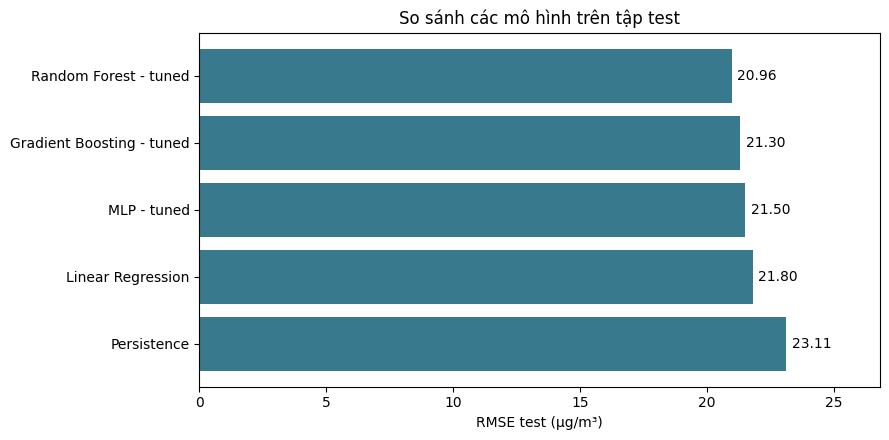

RMSE test thấp nhất: Random Forest - tuned (20.9613 µg/m³).
RMSE thấp nhất giảm 9.31% so với Persistence.


In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(test_metrics["model"], test_metrics["rmse"], color="#39798e")
ax.invert_yaxis()
ax.set_xlabel("RMSE test (µg/m³)")
ax.set_title("So sánh các mô hình trên tập test")
ax.set_xlim(0, test_metrics["rmse"].max() * 1.16)
ax.bar_label(bars, fmt="%.2f", padding=4)
fig.tight_layout()
plt.show()

best = test_metrics.iloc[0]
baseline_rmse = test_metrics.loc[
    test_metrics["experiment_id"].eq("baseline_persistence_test"), "rmse"
].item()
print(f"RMSE test thấp nhất: {best['model']} ({best['rmse']:.4f} µg/m³).")
if baseline_rmse > 0:
    reduction = 100 * (baseline_rmse - best["rmse"]) / baseline_rmse
    print(f"RMSE thấp nhất giảm {reduction:.2f}% so với Persistence.")

## 6. Lưu kết quả và cập nhật nhật ký

Khi `SAVE_ARTIFACTS = True`, lưu bảng điểm vào `outputs/notebooks/tables/final_test_metrics.csv` và hình vào `outputs/notebooks/figures/final_test_rmse.png`. Nhật ký `experiment_log.csv` cập nhật theo mã thí nghiệm có đuôi `_test`. Hai dòng test cho Persistence và Linear Regression dùng cùng mã với notebook 02.

In [13]:
if SAVE_ARTIFACTS:
    figures_dir = OUTPUTS_DIR / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    metrics_path = TABLES_DIR / "final_test_metrics.csv"
    figure_path = figures_dir / "final_test_rmse.png"

    dataset_version = (
        f"beijing_air_quality_standardized.csv; ffill<={FFILL_LIMIT}h; "
        f"lags={'/'.join(map(str, PM25_LAGS))}; rolling={'/'.join(map(str, ROLLING_WINDOWS))}"
    )
    log_rows = (
        test_metrics[["experiment_id", "model", "mae", "rmse", "r2"]]
        .rename(columns={"model": "model_name"})
        .round({"mae": 6, "rmse": 6, "r2": 6})
    )
    log_rows.insert(2, "dataset_version", dataset_version)
    log_rows["notes"] = (
        f"Final test, {len(y_test)} rows with labels from {TEST_START:%Y-%m-%d}. "
        "Configurations fixed before test evaluation."
    )
    if EXPERIMENT_LOG.is_file() and EXPERIMENT_LOG.stat().st_size:
        existing_log = pd.read_csv(EXPERIMENT_LOG, encoding="utf-8-sig")
        existing_log = existing_log.loc[~existing_log["experiment_id"].isin(log_rows["experiment_id"])]
        log_rows = pd.concat([existing_log, log_rows], ignore_index=True)

    test_metrics.to_csv(metrics_path, index=False, encoding="utf-8-sig")
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    log_rows.to_csv(EXPERIMENT_LOG, index=False, encoding="utf-8-sig")
    for path in (metrics_path, figure_path, EXPERIMENT_LOG):
        print("Đã lưu:", path.relative_to(PROJECT_ROOT))

Đã lưu: outputs\final_test_metrics.csv
Đã lưu: outputs\figures\final_test_rmse.png
Đã lưu: experiment_log.csv
